# E1 — Free-motion transparency

Sinusoids along the heaviest and lightest directions of Λ₀ (`e1_free_motion.py`). Expected: M1's e_F
grows with the delay T; M3's grows with the frequency (it renders no inertia); M5 stays low; M4, retuned
per direction, should match M5 in these two directions. On the robot, friction sets M5's floor.

In [1]:
# Runs to analyse: run directories, session files (exp/<exp>/sessions/*.txt, written by the script) or a
# folder of runs (a folder also holds retried and superseded runs). Default: the latest session file,
# which lists every condition once.
from common import latest_session

RUNS = [latest_session("e1")]
RECOMPUTE = False  # True: recompute the metrics from the data instead of reading analysis/metrics.json

In [ ]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # before anything imports JAX: the GPU stays free for fr3_teleop's IK
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/exp
sys.path[:0] = [str(HERE), str(HERE.parent)]
import matplotlib.pyplot as plt  # noqa: I001
import numpy as np
import pandas as pd

import exp_metrics
import plots as P
from common import collect, load_table

%matplotlib inline
%load_ext autoreload
%autoreload 2  # pick up edits to exp_metrics / plots / common without a kernel restart
pd.set_option("display.precision", 3)

runs = collect(RUNS)
df = load_table(runs, exp_metrics.e1 if RECOMPUTE else None)
print(f"{len(df)} runs")

60 runs


In [3]:
df["direction"] = df.label.str.split("_").str[0]
df[
    [
        "run",
        "method",
        "rtt",
        "direction",
        "frequency_hz",
        "accel_peak",
        "eF_n_rms",
        "eF_rms",
        "f_n_rms",
        "Fosc_n_rms",
        "lag_ms",
        "E_end_J",
    ]
].sort_values(["direction", "frequency_hz", "method", "rtt"])

,run,method,rtt,direction,frequency_hz,accel_peak,eF_n_rms,eF_rms,f_n_rms,Fosc_n_rms,lag_ms,E_end_J
6,20261026_130543_e1_proxy-fixed-mass_rtt0_heavy...,proxy-fixed-mass,0,heavy,0.25,0.123,9.025,9.369,1.308,8.809,0.966,-10.308
7,20261026_130643_e1_proxy-fixed-mass_rtt2600_he...,proxy-fixed-mass,2600,heavy,0.25,0.123,9.053,9.380,1.308,8.829,1302.093,-10.387
4,20261026_130346_e1_proxy-god-object_rtt0_heavy...,proxy-god-object,0,heavy,0.25,0.123,8.632,9.019,0.000,8.632,1.138,-9.937
5,20261026_130441_e1_proxy-god-object_rtt2600_he...,proxy-god-object,2600,heavy,0.25,0.123,8.582,8.945,0.000,8.582,1302.128,-9.933
8,20261026_130941_e1_proxy-rim_rtt0_heavy_f0.25,proxy-rim,0,heavy,0.25,0.123,9.085,9.438,1.308,8.869,1.157,-10.461
9,20261026_131102_e1_proxy-rim_rtt2600_heavy_f0.25,proxy-rim,2600,heavy,0.25,0.123,9.173,9.529,1.300,8.945,1302.169,-10.569
0,20261026_125904_e1_zoh_rtt0_heavy_f0.25,zoh,0,heavy,0.25,0.123,0.244,0.258,8.574,8.365,0.944,0.889
2,20261026_135415_e1_zoh_rtt850_heavy_f0.25,zoh,850,heavy,0.25,0.123,41.960,42.056,48.670,8.332,426.970,37.684
3,20261026_130226_e1_zoh_rtt2600_heavy_f0.25,zoh,2600,heavy,0.25,0.123,58.793,58.903,56.976,8.433,1302.098,-39.188
1,20261026_130018_e1_zoh_rtt5g_heavy_f0.25,zoh,5g,heavy,0.25,0.123,2.990,3.012,10.976,8.283,24.139,4.140


## RMS e_F against the delay
One panel per direction and frequency; one line per method.

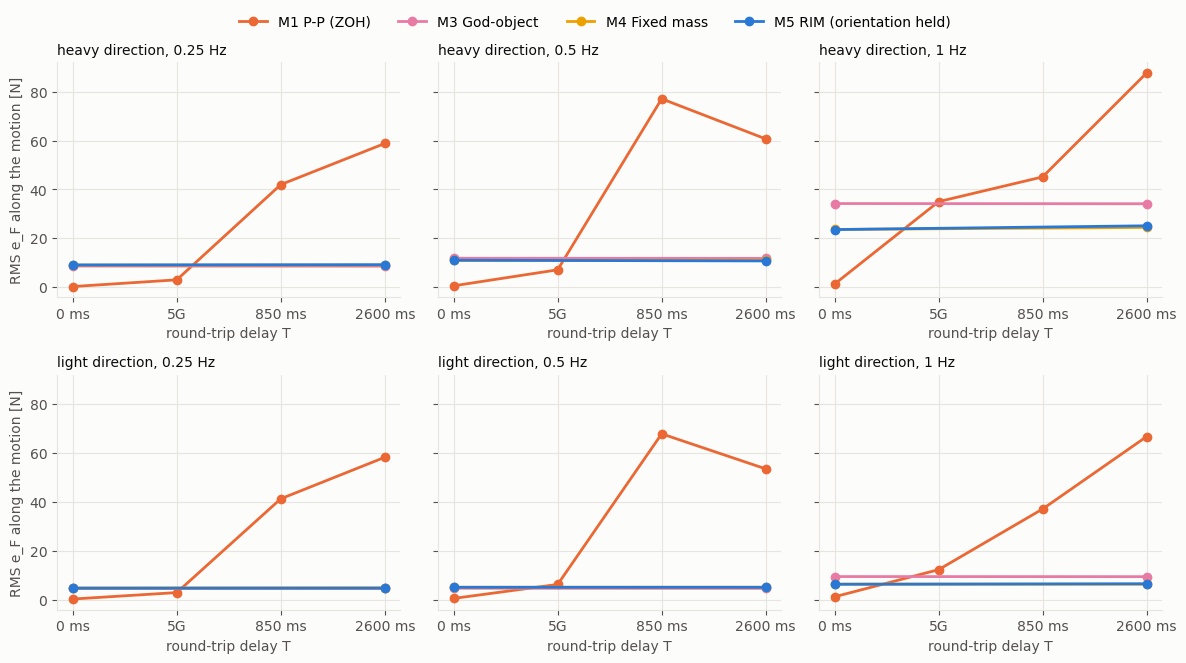

In [4]:
dirs, freqs = sorted(df.direction.unique()), sorted(df.frequency_hz.unique())
fig, axes = plt.subplots(len(dirs), len(freqs), figsize=(4 * len(freqs), 3.2 * len(dirs)), squeeze=False, sharey=True)
for i, d in enumerate(dirs):
    for j, f in enumerate(freqs):
        ax = axes[i, j]
        P.by_delay(ax, df[(df.direction == d) & (df.frequency_hz == f)], "eF_n_rms", label_methods=(i == 0 and j == 0))
        ax.set_title(f"{d} direction, {f:g} Hz", loc="left", fontsize=10)
    axes[i, 0].set_ylabel("RMS e_F along the motion [N]")
fig.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()

## RMS e_F against the frequency
At each delay; the felt force `f` is shown dashed for scale.

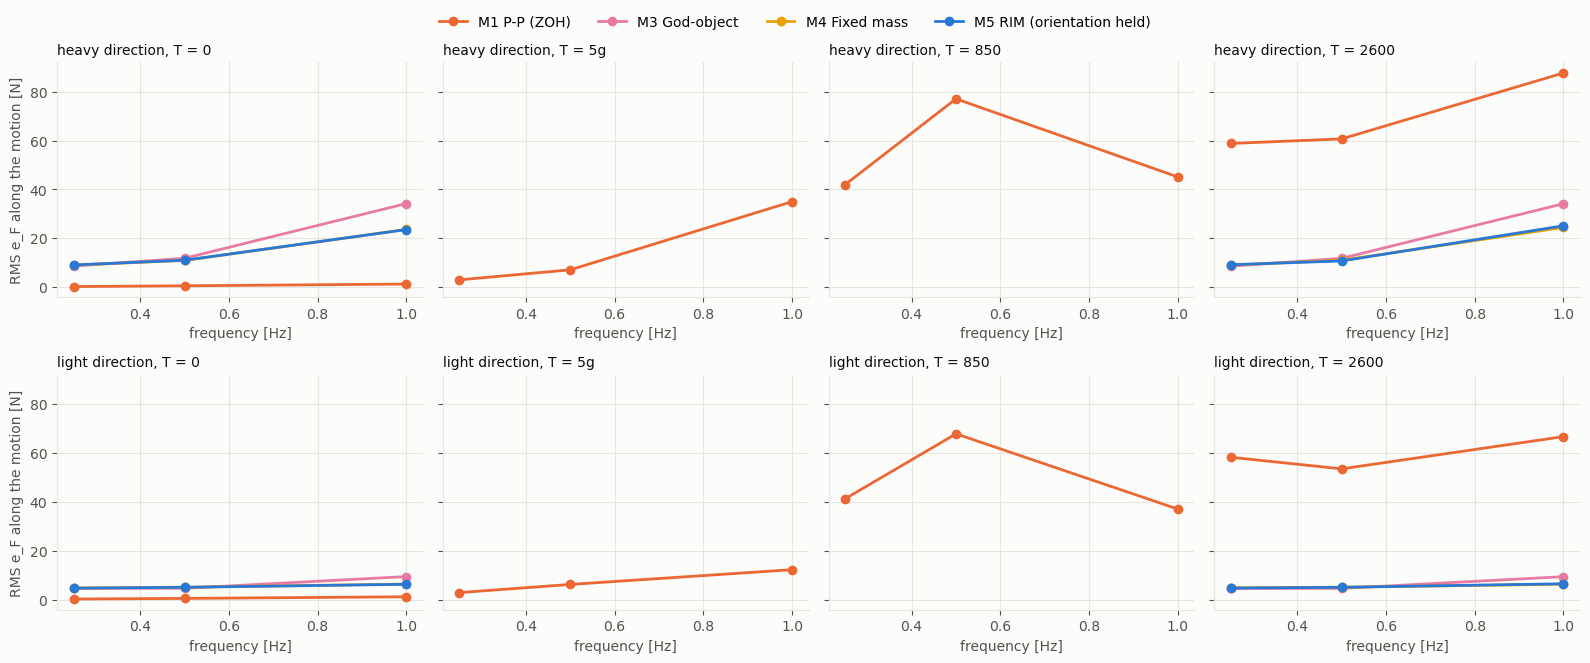

In [5]:
delays = [d for d in P.DELAYS if d in set(df.rtt.map(P.delay_key))]
fig, axes = plt.subplots(len(dirs), len(delays), figsize=(4 * len(delays), 3.2 * len(dirs)), squeeze=False, sharey=True)
for i, d in enumerate(dirs):
    for j, T in enumerate(delays):
        ax = axes[i, j]
        sub = df[(df.direction == d) & (df.rtt.map(P.delay_key) == T)]
        for m in P.methods_in(sub):
            s = sub[sub.method == m].groupby("frequency_hz")[["eF_n_rms", "f_n_rms"]].mean()
            ax.plot(s.index, s.eF_n_rms, "o-", color=P.color(m), label=P.LABELS.get(m, m) if (i, j) == (0, 0) else None)
        ax.set_title(f"{d} direction, T = {T}", loc="left", fontsize=10)
        ax.set_xlabel("frequency [Hz]")
    axes[i, 0].set_ylabel("RMS e_F along the motion [N]")
fig.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()

## Run checks

Every run should have ended normally ("run ended"), with M3–M5 at the frozen OSC stiffness and M1 at
its coupling K, and a measured lag equal to the configured one. `e1_checks` loads every run (a minute
or two): besides these, it measures the motion amplitudes and the robot's impedance used below.

In [6]:
from runs import load_run

chk = pd.DataFrame([{"run": Path(r).name, **exp_metrics.e1_checks(load_run(r))} for r in runs])
df = df.drop(columns=[c for c in chk.columns if c != "run" and c in df.columns]).merge(chk, on="run")
df["T_ms"] = 2 * df.lag_ms  # measured round trip (5G: its median)
print(df.groupby(["method", "osc_k_pos_x", "stop_reason"]).size().to_string())
print("one-way lag, median [ms]:", df.groupby(df.rtt.astype(str)).lag_ms.median().round(1).to_dict())
print("runs with the chatter guard tripped (felt force zeroed for 3 s per trip):")
df.loc[df.guard_s > 0, ["run", "guard_s", "eF_n_rms"]]

method            osc_k_pos_x  stop_reason
proxy-fixed-mass  2000.0       run ended      12
proxy-god-object  2000.0       run ended      12
proxy-rim         2000.0       run ended      12
zoh               1000.0       run ended      24
one-way lag, median [ms]: {'0': 1.1, '2600': 1302.1, '5g': 24.2, '850': 427.1}
runs with the chatter guard tripped (felt force zeroed for 3 s per trip):


,run,guard_s,eF_n_rms
21,20261026_132151_e1_zoh_rtt5g_heavy_f1,3.001,34.991
22,20261026_132218_e1_zoh_rtt850_heavy_f1,3.001,45.110
51,20261026_134930_e1_zoh_rtt5g_light_f1,6.001,12.262


## M1 against the delayed-sine prediction

Under delay the robot follows the leader one round trip late, so M1's unfelt force is the coupling
spring stretched between the leader now and one round trip ago:
$e_F \approx K\,\big(x_l(t-T) - x_l(t)\big)$, of RMS $K \cdot 2A\,|\sin(\omega T/2)| / \sqrt 2$.
For a periodic leader it is periodic in $T$: the delayed robot comes partly back into phase, so M1's
$e_F$ is not monotonic in $T$ at 0.5 and 1 Hz (it is at 0.25 Hz, where $\omega T/2 < \pi/2$ up to
2.6 s). The prediction assumes the robot tracks the leader's amplitude: it holds at 0.25–0.5 Hz; at
1 Hz the robot overshoots (next section) and $e_F$ is 30–40 % above it, more for the chatter-guard runs.

,direction,frequency_hz,rtt,eF_n_rms,eF_pred,guard_s
0,heavy,0.25,0,0.244,0.105,0.000
1,heavy,0.25,5g,2.990,2.681,0.000
2,heavy,0.25,850,41.960,43.948,0.000
3,heavy,0.25,2600,58.793,62.898,0.000
10,heavy,0.50,0,0.548,0.228,0.000
11,heavy,0.50,5g,7.095,5.334,0.000
13,heavy,0.50,2600,60.670,57.490,0.000
12,heavy,0.50,850,77.067,68.871,0.000
20,heavy,1.00,0,1.263,0.443,0.000
21,heavy,1.00,5g,34.991,11.134,3.001


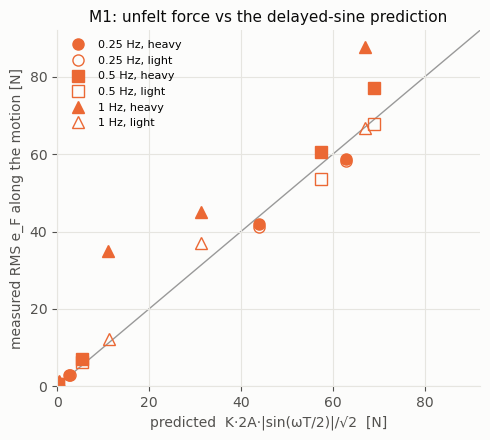

In [7]:
z = df[df.method == "zoh"].copy()
z["eF_pred"] = z.K * 2 * z.amplitude_m * np.abs(np.sin(np.pi * z.frequency_hz * z.T_ms / 1e3)) / np.sqrt(2)
markers = {0.25: "o", 0.5: "s", 1.0: "^"}
fig, ax = plt.subplots(figsize=(5, 4.5))
for f, mk in markers.items():
    for d, fill in [("heavy", True), ("light", False)]:
        s = z[(z.frequency_hz == f) & (z.direction == d)]
        ax.plot(
            s.eF_pred,
            s.eF_n_rms,
            mk,
            ms=8,
            color=P.color("zoh"),
            mfc=P.color("zoh") if fill else "none",
            label=f"{f:g} Hz, {d}",
        )
lim = [0, 1.05 * max(z.eF_pred.max(), z.eF_n_rms.max())]
ax.plot(lim, lim, color="0.6", lw=1, zorder=0)
ax.set(
    xlim=lim,
    ylim=lim,
    xlabel="predicted  K·2A·|sin(ωT/2)|/√2  [N]",
    ylabel="measured RMS e_F along the motion [N]",
    title="M1: unfelt force vs the delayed-sine prediction",
)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
z[["direction", "frequency_hz", "rtt", "eF_n_rms", "eF_pred", "guard_s"]].sort_values(
    ["direction", "frequency_hz", "eF_pred"]
)

## Motion amplitudes: the coupling resonance

A scripted leader drives M4's and M5's proxy through the coupling (K, D): a mass m on K resonates at
$\sqrt{K/m}/2\pi$ — 1.3 Hz along the heavy direction (14.5 kg), 2.3 Hz along the light one (4.8 kg).
Near it the proxy, and the robot that follows it, swing wider than the leader; M3's massless proxy
does not, and M1's robot is the real arm on the OSC spring K. So at 1 Hz, along the heavy direction,
the methods do not move the robot the same way: $e_F$ still measures each method's model error, but
on different motions.

method                  proxy-fixed-mass  proxy-god-object  proxy-rim   zoh  \
direction frequency_hz                                                        
heavy     0.25                      47.6              46.7       47.7  43.8   
          0.50                      54.1              49.6       54.0  52.1   
          1.00                      88.4              59.4       88.2  75.6   
light     0.25                      47.9              47.5       47.8  44.7   
          0.50                      49.6              48.4       49.7  47.3   
          1.00                      57.1              51.9       57.2  54.2   

method                  leader_mm  
direction frequency_hz             
heavy     0.25             49.975  
          0.50             49.974  
          1.00             49.973  
light     0.25             49.975  
          0.50             49.974  
          1.00             49.973

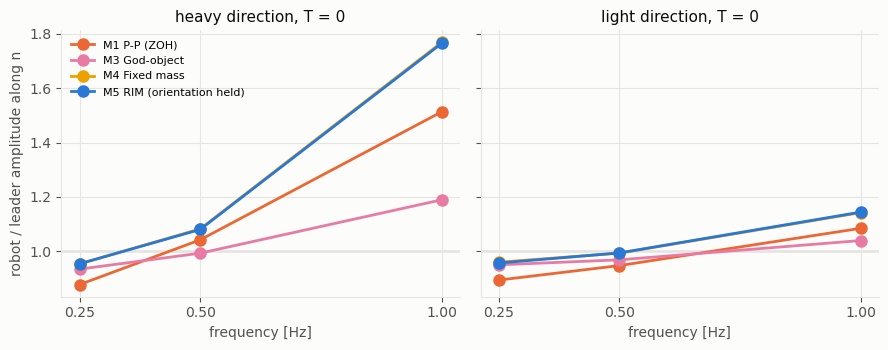

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, d in zip(axes, ["heavy", "light"]):
    sub = df[(df.direction == d) & (df.rtt.map(P.delay_key) == "0")]
    for m in P.methods_in(sub):
        s = sub[sub.method == m].sort_values("frequency_hz")
        ax.plot(s.frequency_hz, s.A_robot / s.A_leader, "o-", lw=2, ms=8, color=P.color(m), label=P.LABELS.get(m, m))
    ax.axhline(1, color="0.6", lw=1, zorder=0)
    ax.set(title=f"{d} direction, T = 0", xlabel="frequency [Hz]", xticks=sorted(df.frequency_hz.unique()))
axes[0].set_ylabel("robot / leader amplitude along n")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
amp = df[df.rtt.map(P.delay_key) == "0"].pivot_table(
    index=["direction", "frequency_hz"], columns="method", values="A_robot"
)
(1e3 * amp).round(1).assign(leader_mm=1e3 * df.groupby(["direction", "frequency_hz"]).A_leader.median())

## The robot's effective mass and friction (unmodelled dynamics)

At the drive frequency, the robot's first-harmonic impedance along n, $Z = F_{osc}/x$, is
$\mathrm{Re}\,Z = k - m\,\omega^2$ for an effective mass m, and $\mathrm{Im}\,Z$ is friction (Coulomb
friction $F_c$ gives $\mathrm{Im}\,Z \approx 4F_c/(\pi|X|)$, constant in frequency). $F_{osc}$ is all
the force the controller put on the arm along n: for M3 and M1 it is the whole force, for M5 it
includes the feedforward. Fitting $\mathrm{Re}\,Z$ over the three frequencies gives the arm's real
effective mass, to compare with the model's $n^\top\Lambda_0 n$ (orientation held, the one M4 and M5 use).

,method,direction,m_eff_kg,k_N/m,model_kg,ratio,coulomb_N (per freq)
0,proxy-fixed-mass,heavy,20.84,40.62,14.46,1.44,"[9.0, 10.5, 15.2]"
1,proxy-fixed-mass,light,6.80,61.70,4.79,1.42,"[4.7, 5.1, 6.3]"
2,proxy-god-object,heavy,20.28,39.83,14.46,1.40,"[8.8, 10.3, 12.9]"
3,proxy-god-object,light,6.76,63.64,4.79,1.41,"[4.7, 5.0, 6.2]"
4,proxy-rim,heavy,21.14,42.17,14.46,1.46,"[9.1, 10.5, 15.0]"
5,proxy-rim,light,6.89,63.20,4.79,1.44,"[4.5, 5.1, 6.3]"
6,zoh,heavy,20.44,38.22,14.46,1.41,"[8.6, 10.8, 15.3]"
7,zoh,light,6.78,68.46,4.79,1.41,"[4.4, 4.9, 6.2]"


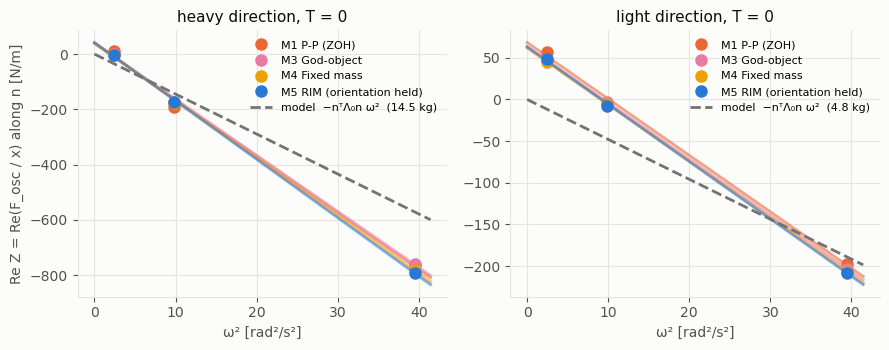

In [9]:
from common import held_mass_with_armature, start_inertia
from e1_free_motion import START

lam0 = start_inertia(START)
dirs_n = {"heavy": lam0["eigvecs"][:, 2], "light": lam0["eigvecs"][:, 0]}
model_mass = {d: float(n @ lam0["Lambda_rim"] @ n) for d, n in dirs_n.items()}

t0 = df[df.rtt.map(P.delay_key) == "0"].copy()
t0["w2"] = (2 * np.pi * t0.frequency_hz) ** 2
fit = []
for (m, d), g in t0.groupby(["method", "direction"]):
    (k, slope), *_ = np.linalg.lstsq(np.c_[np.ones(len(g)), g.w2], g.ReZ, rcond=None)
    fit.append(
        {
            "method": m,
            "direction": d,
            "m_eff_kg": -slope,
            "k_N/m": k,
            "model_kg": model_mass[d],
            "ratio": -slope / model_mass[d],
            "coulomb_N (per freq)": g.sort_values("w2").coulomb_N.round(1).tolist(),
        }
    )
fit = pd.DataFrame(fit)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, d in zip(axes, ["heavy", "light"]):
    sub = t0[t0.direction == d]
    w2 = np.linspace(0, sub.w2.max() * 1.05, 50)
    for m in P.methods_in(sub):
        s = sub[sub.method == m].sort_values("w2")
        ax.plot(s.w2, s.ReZ, "o", ms=8, color=P.color(m), label=P.LABELS.get(m, m))
        r = fit[(fit.method == m) & (fit.direction == d)].iloc[0]
        ax.plot(w2, r["k_N/m"] - r.m_eff_kg * w2, lw=2, color=P.color(m), alpha=0.6)
    ax.plot(w2, -model_mass[d] * w2, "--", lw=2, color="0.45", label=f"model  −nᵀΛ₀n ω²  ({model_mass[d]:.1f} kg)")
    ax.set(title=f"{d} direction, T = 0", xlabel="ω² [rad²/s²]")
axes[0].set_ylabel("Re Z = Re(F_osc / x) along n [N/m]")
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fit.round(2)

The URDF behind the RIM model has no rotor inertia (its `<dynamics>` tags carry damping and friction
only). Adding a uniform reflected rotor inertia (armature) to the mass matrix's diagonal shows how
much of the gap it can explain:

In [10]:
arm = held_mass_with_armature(START, dirs_n, [0.0, 0.1, 0.2, 0.25, 0.3])
measured = fit.groupby("direction").m_eff_kg.mean()
arm.round(2).assign(**{f"measured_{d}": round(measured[d], 2) for d in dirs_n})

,heavy,light,measured_heavy,measured_light
armature,,,,
0.00,14.46,4.79,20.67,6.8
0.10,16.72,5.72,20.67,6.8
0.20,18.98,6.58,20.67,6.8
0.25,20.11,7.01,20.67,6.8
0.30,21.23,7.43,20.67,6.8


## Discussion

Results of the 2026-10-26 session (60 runs, one per condition; numbers below are from it).

**What the plan expected, and holds.**
- M3–M5 are flat in the delay: T = 0 and 2.6 s differ by less than 1.5 N in every condition.
- M1 grows with the delay as the delayed-sine prediction says ($K\cdot 2A|\sin(\omega T/2)|/\sqrt2$,
  within ~10 % at 0.25–0.5 Hz; 30–40 % above it at 1 Hz, where the robot overshoots); it is monotonic in T only at 0.25 Hz (0.2 → 3 → 42 → 59 N, heavy): use that one for
  the "M1 grows with T" slide, or plot against $|\sin(\omega T/2)|$.
- At low frequency M3, M4 and M5 coincide on a floor set by friction (~9 N heavy, ~4.6 N light);
  the model starts to matter at 1 Hz, where M4/M5 cut $e_F$ by about a third against M3
  (23.6 vs 34.2 N heavy, 6.3 vs 9.4 N light).
- M4 ≈ M5 here, as designed: M4's mass is retuned to $n^\top\Lambda_0 n$ along each direction.
  E2 and E4 carry M4 vs M5.

**Unmodelled dynamics.** The residual of M4 and M5 is not the delay; it is what the model leaves out:
- *Friction.* Mostly Coulomb, with a viscous part: the Coulomb-equivalent force is ~9 N along the
  heavy direction and ~4.6 N along the light one at 0.25 Hz, rising to ~15 N and ~6 N at 1 Hz. It is the whole floor at 0.25–0.5 Hz, the honest floor of a frictionless
  model (the plan's "friction floor" risk).
- *Inertia.* The arm is ~1.43× heavier than the RIM model in both directions (≈ 20.5 vs 14.5 kg,
  ≈ 6.9 vs 4.8 kg), measured the same under M1, M3 and M5. The likely cause is the motors' reflected
  rotor inertia, which the URDF omits: a uniform 0.25 kg·m² per joint reproduces both directions.
  A hypothesis, not an identified value; it is left out of the model on purpose and reported as
  unmodelled dynamics. M4 inherits the same deficit (its m is from the same Λ₀).

**Caveats.**
- *Coupling resonance.* Along the heavy direction at 1 Hz the M4/M5 proxy (14.5 kg on K = 1000 N/m,
  resonance 1.3 Hz) swings ~1.8× the leader, and the robot with it; M3's and M1's robots move less.
  The methods' $e_F$ at that point are model errors on different motions. (M4's line lies under M5's: same mass along each direction.)
- *Chatter guard.* In three M1 runs (5G heavy 1 Hz, 850 ms heavy 1 Hz, 5G light 1 Hz) the guard
  zeroed the felt force for 3–6 s, inflating $e_F$: 5G's delay jumps make the force reverse fast. The
  guard is off from E2 on (scripted runs, no device to protect).
- *Energy.* The negative $E$ of M3–M5 (−5 to −16 J) is the controller's work against friction that the
  operator never felt, not instability.